<img src="https://raw.githubusercontent.com/piddy376/visits-weather-notebooks/main/assets/gg_lockup.png" alt="Global Gateway · European Union" height="64"/>

**Financé par l'Union européenne** · Programme de partenariat spatial Afrique–UE · Renforcement des alertes précoces en Afrique (SEWA)

# Les poussières désertiques sur l'Afrique de l'Ouest avec CAMS 🏜️
### Service Copernicus de surveillance de l'atmosphère · compte gratuit

> ⚠️ **Traduction :** ce notebook a été traduit de l'anglais avec l'aide de l'IA et relu au mieux de nos possibilités. En cas de doute, la [version anglaise](https://colab.research.google.com/github/piddy376/visits-weather-notebooks/blob/main/senegal/dust_cams.ipynb) fait foi. Signalez toute erreur sur [GitHub](https://github.com/piddy376/visits-weather-notebooks/issues).

🌐 [English](https://colab.research.google.com/github/piddy376/visits-weather-notebooks/blob/main/senegal/dust_cams.ipynb) · [Français](https://colab.research.google.com/github/piddy376/visits-weather-notebooks/blob/main/senegal/dust_cams_fr.ipynb) · [Português](https://colab.research.google.com/github/piddy376/visits-weather-notebooks/blob/main/senegal/dust_cams_pt.ipynb)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/piddy376/visits-weather-notebooks/blob/main/senegal/dust_cams_fr.ipynb)

En saison sèche, à peu près de novembre à mars, l'**harmattan**, vent de nord-est, transporte les poussières du
Sahara à travers le Sahel vers l'Atlantique. Ce notebook cartographie la prévision de poussières de la **prévision
mondiale CAMS**, produite par l'ECMWF pour l'Union européenne, à partir du run d'hier et jusqu'à cinq jours.

**Ce qu'il vous faut :** un compte Google (pour utiliser Colab) et un compte Copernicus gratuit (étape ci-dessous). Tout tourne sur les ordinateurs de Google : les données y sont téléchargées, pas sur votre
téléphone ou votre ordinateur, donc une connexion lente ou mobile suffit.

| Données | Ce que ce notebook utilise | Licence |
|---|---|---|
| Prévision mondiale CAMS de la composition atmosphérique, environ 40 km | Épaisseur optique des aérosols désertiques à 550 nm | licence Copernicus, gratuit |

**Outils :** [earthkit](https://earthkit.ecmwf.int), les outils Python libres et gratuits de l'ECMWF pour les données météo et climat.

*Cliquez sur **Exécution → Tout exécuter** (Runtime → Run all). Le data store met les demandes en file d'attente : l'étape 2 peut prendre quelques minutes.*

<img src="https://raw.githubusercontent.com/piddy376/visits-weather-notebooks/main/assets/cams_logoline_pos.png" alt="Copernicus, implemented by ECMWF" height="30"/>

In [ ]:
# Installer les outils libres (Colab / nouvelle machine). Quelques minutes la première fois.
%pip install -q "earthkit-data[cds]" earthkit-plots

## Votre clé Copernicus gratuite

Les données Copernicus sont libres et gratuites, mais les data stores demandent de s'inscrire une fois pour gérer la file d'attente :
1. Créez un compte sur [cds.climate.copernicus.eu](https://cds.climate.copernicus.eu) (le même identifiant sert pour
   l'Atmosphere Data Store).
2. Ouvrez la [page du jeu de données](https://ads.atmosphere.copernicus.eu/datasets/cams-global-atmospheric-composition-forecasts?tab=download) sur l'Atmosphere Data Store et acceptez sa licence (en bas de l'onglet Download). Une seule fois suffit.
3. Copiez votre clé API depuis votre [page de profil](https://cds.climate.copernicus.eu/profile) et collez-la ci-dessous.

**Utilisez votre propre clé.** Chaque personne qui exécute ce notebook a besoin de son propre compte et de sa clé
Copernicus gratuits. La cellule suivante demande la clé dans un champ masqué et l'enregistre sur la machine qui exécute
le notebook (dans Colab, une machine temporaire effacée à la fermeture de l'onglet). La clé n'est jamais enregistrée dans
le notebook : ne la collez pas dans une cellule de code et ne partagez pas de notebook ou de capture d'écran qui la montre.
Sur votre ordinateur, si `~/.cdsapirc` / `~/.adsapirc` existent déjà, la cellule ne demande rien.

In [2]:
import os
from getpass import getpass
rc = {"~/.cdsapirc": "https://cds.climate.copernicus.eu/api", "~/.adsapirc": "https://ads.atmosphere.copernicus.eu/api"}
missing = [p for p in rc if not os.path.exists(os.path.expanduser(p))]
if missing:
    key = getpass("Clé API Copernicus : ")
    for p in missing:
        with open(os.path.expanduser(p), "w") as f:
            f.write(f"url: {rc[p]}\nkey: {key}\n")
print("Clé Copernicus prête")

Clé Copernicus prête


In [3]:
import pyproj                     # à importer avant earthkit.data (évite un plantage à la fermeture)
import datetime as dt
import earthkit.data as ekd
import earthkit.plots as ekp
import cartopy.crs as ccrs
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
import numpy as np

JOURS = ["lundi", "mardi", "mercredi", "jeudi", "vendredi", "samedi", "dimanche"]
MOIS = ["janvier", "février", "mars", "avril", "mai", "juin", "juillet", "août", "septembre", "octobre",
        "novembre", "décembre"]
def jour(d): return f"{JOURS[d.weekday()]} {d.day} {MOIS[d.month - 1]}"     # dates en français
def date(d): return f"{d.day} {MOIS[d.month - 1]} {d.year}"

## 1 · Choisir le run, l'échéance et la zone

In [4]:
AREA = [27.0, -26.0, 4.0, 10.0]                                   # nord, ouest, sud, est
DATE = (dt.date.today() - dt.timedelta(days=1)).isoformat()      # le run d'hier est toujours complet
LEAD = 72                                                         # heures après 00 h UTC, jusqu'à 120
CITIES = [("Dakar", 14.716, -17.467), ("Saint-Louis", 16.018, -16.489), ("Touba", 14.850, -15.883),
          ("Tambacounda", 13.771, -13.667), ("Ziguinchor", 12.583, -16.272), ("Kédougou", 12.557, -12.174)]

def label_cities(ax):
    for name, la, lo in CITIES:
        ax.scatter([lo], [la], s=36, color="#ffd23f", edgecolors="#1a1a1a", linewidths=0.8, zorder=10,
                   transform=ccrs.PlateCarree())
        ax.text(lo, la, f"  {name}", transform=ccrs.PlateCarree(), fontsize=10, fontweight="bold", zorder=11,
                color="#1d2230", path_effects=[pe.withStroke(linewidth=2.5, foreground="white")])

## 2 · Télécharger la prévision de poussières

In [5]:
cams = ekd.from_source("ads", "cams-global-atmospheric-composition-forecasts", {
    "variable": "dust_aerosol_optical_depth_550nm", "date": f"{DATE}/{DATE}", "time": "00:00",
    "type": "forecast", "leadtime_hour": str(LEAD), "area": AREA, "data_format": "grib"}).to_xarray()
duaod = cams[list(cams.data_vars)[0]].squeeze()
valid = dt.datetime.fromisoformat(DATE) + dt.timedelta(hours=LEAD)
print(f"Épaisseur optique des poussières jusqu'à {float(duaod.max()):.2f} le {jour(valid)} à {valid:%H} h UTC")

Épaisseur optique des poussières jusqu'à 0.44 le dimanche 22 novembre à 00 h UTC


## 3 · La cartographier

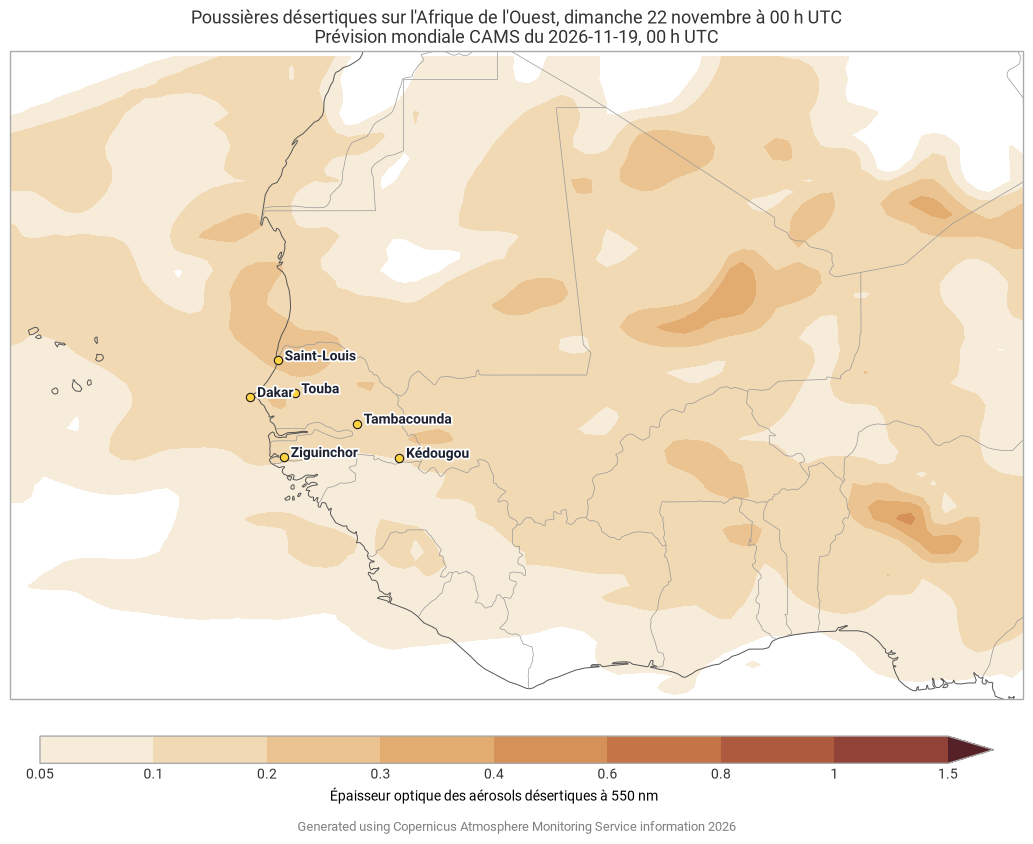

In [6]:
colors = ["#f6ecd9", "#efd3a8", "#e6b77d", "#d9955a", "#c27046", "#a34f3c", "#7d3533", "#562126"]
style = ekp.styles.Style(levels=[0.05, 0.1, 0.2, 0.3, 0.4, 0.6, 0.8, 1.0, 1.5], colors=colors, extend="max")
chart = ekp.Map(domain=[AREA[1], AREA[3], AREA[2], AREA[0]], figsize=(12, 8))
chart.contourf(duaod, style=style)
chart.coastlines(linewidth=0.7); chart.borders(linewidth=0.5)
label_cities(chart.ax)
chart.legend(label="Épaisseur optique des aérosols désertiques à 550 nm")
chart.title(f"Poussières désertiques sur l'Afrique de l'Ouest, {jour(valid)} à {valid:%H} h UTC\nPrévision mondiale CAMS du {DATE}, 00 h UTC", fontsize=13)
chart.attribution("Generated using Copernicus Atmosphere Monitoring Service information 2026")
chart.save("dust_cams_fr.png")
chart.show()

## 4 · À vous de jouer 🌍

- **Parcourir la semaine :** changez `LEAD` de 0 à 120 par pas de 3.
- **Les poussières près du sol :** la variable `"dust_aerosol_0.9-20um_mixing_ratio"` donne les grosses poussières ; ou
  essayez `"particulate_matter_10um"` (multipliez par 1e9 pour des µg/m³), surtout des poussières en saison sèche au Sahel.
- CAMS mondial a une résolution d'environ 40 km : il montre où vont les poussières, pas le détail ville par ville.

### Données et licence
Les données Copernicus sont libres et gratuites sous licence Copernicus (CC-BY 4.0). Mention :
*Generated using Copernicus Atmosphere Monitoring Service information 2026.* L'ECMWF opère le service Copernicus de surveillance de l'atmosphère (CAMS) et le
service Copernicus concernant le changement climatique (C3S) pour l'Union européenne.

[Climate Data Store](https://cds.climate.copernicus.eu) · [Atmosphere Data Store](https://ads.atmosphere.copernicus.eu) ·
[earthkit](https://earthkit.ecmwf.int)